In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix,accuracy_score,classification_report
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

In [ ]:
df = pd.read_csv('W.csv')
df.head()

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,54865,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,55054,109,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,55055,52,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,46236,34,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,54863,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


In [ ]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(146956, 75)
(36739, 75)
(146956,)
(36739,)


In [ ]:
#Buildig ANN
ann=Sequential()
ann.add(Dense(units=6,activation='relu')) #unit represents the no. of perceptron (input)
ann.add(Dense(units=6,activation='relu')) #hidden layer
ann.add(Dense(units=1,activation='sigmoid'))#output layer

In [ ]:
#Compile model
ann.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

In [ ]:
#Train
history = ann.fit(x_train,y_train_encoded,batch_size=32,epochs=10,validation_split=0.2)

Epoch 1/10
3674/3674 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.9993 - loss: 0.0024 - val_accuracy: 0.9993 - val_loss: 0.0024
Epoch 2/10
3674/3674 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - accuracy: 0.9993 - loss: 0.0023 - val_accuracy: 0.9993 - val_loss: 0.0021
Epoch 3/10
3674/3674 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - accuracy: 0.9993 - loss: 0.0022 - val_accuracy: 0.9993 - val_loss: 0.0024
Epoch 4/10
3674/3674 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - accuracy: 0.9993 - loss: 0.0022 - val_accuracy: 0.9994 - val_loss: 0.0021
Epoch 5/10
3674/3674 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - accuracy: 0.9993 - loss: 0.0022 - val_accuracy: 0.9994 - val_loss: 0.0023
Epoch 6/10
3674/3674 ━━━━━━━━━━━━━━━━━━━━ 11s 3ms/step - accuracy: 0.9993 - loss: 0.0021 - val_accuracy: 0.9993 - val_loss: 0.0025
Epoch 7/10
3674/3674 ━━━━━━━━━━━━━━━━━━━━ 8s 2ms/step - accuracy: 0.9993 - loss: 0.0022 - val_accuracy: 0.9995 - val_loss: 0.0023
Epoch 8/10
3674/3674 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.9993 - loss: 0.0022 

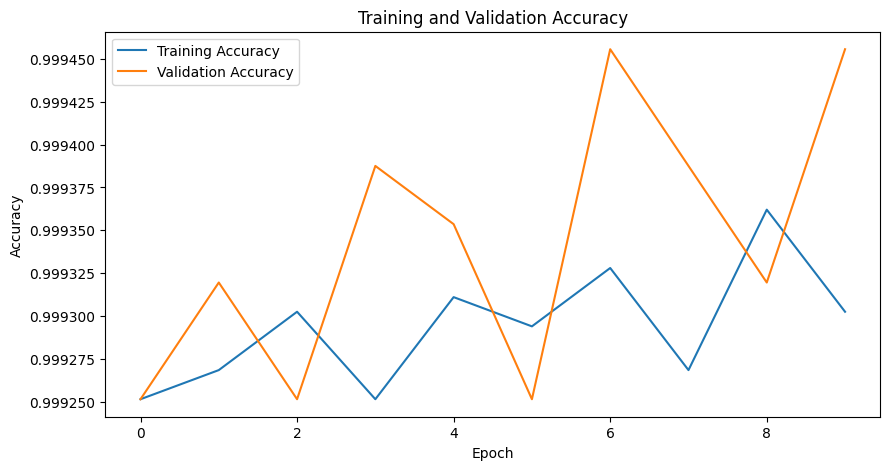

In [ ]:
#Accuracy
plt.figure(figsize=(10,5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()